1. Загрузка библиотек

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

2–4. Загрузка данных и выбор признаков

In [3]:
df = pd.read_csv('titanic.csv')

features = ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch']
target = 'Survived'

data = df[features + [target]].copy()

5. Проверка пропущенных значений

In [4]:
print(data.isnull().sum())

Pclass        0
Age         177
Sex           0
Fare          0
SibSp         0
Parch         0
Survived      0
dtype: int64


6. Обработка пропусков в Age

In [5]:
data['Age'] = data['Age'].fillna(data['Age'].median())

7. Преобразование Sex в числовой вид

In [6]:
data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})

Проверка подготовленных данных


In [7]:
print(data.dtypes)
print(data.isnull().sum())
print(data.head())

Pclass        int64
Age         float64
Sex           int64
Fare        float64
SibSp         int64
Parch         int64
Survived      int64
dtype: object
Pclass      0
Age         0
Sex         0
Fare        0
SibSp       0
Parch       0
Survived    0
dtype: int64
   Pclass   Age  Sex     Fare  SibSp  Parch  Survived
0       3  22.0    0   7.2500      1      0         0
1       1  38.0    1  71.2833      1      0         1
2       3  26.0    1   7.9250      0      0         1
3       1  35.0    1  53.1000      1      0         1
4       3  35.0    0   8.0500      0      0         0


Формирование таблицы для корреляционного анализа

In [8]:
print(data.columns.tolist())
# ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch', 'Survived']

['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch', 'Survived']


Расчёт корреляционной матрицы

In [9]:
corr_matrix = data.corr()
print(corr_matrix.round(2))

          Pclass   Age   Sex  Fare  SibSp  Parch  Survived
Pclass      1.00 -0.34 -0.13 -0.55   0.08   0.02     -0.34
Age        -0.34  1.00 -0.08  0.10  -0.23  -0.17     -0.06
Sex        -0.13 -0.08  1.00  0.18   0.11   0.25      0.54
Fare       -0.55  0.10  0.18  1.00   0.16   0.22      0.26
SibSp       0.08 -0.23  0.11  0.16   1.00   0.41     -0.04
Parch       0.02 -0.17  0.25  0.22   0.41   1.00      0.08
Survived   -0.34 -0.06  0.54  0.26  -0.04   0.08      1.00


Анализ корреляции с Survived

In [10]:
survived_corr = corr_matrix['Survived'].drop('Survived')  # исключаем саму себя
print(survived_corr.round(2))

# Наиболее сильная положительная корреляция
print('Max positive:', survived_corr.idxmax(), survived_corr.max())

# Наиболее сильная отрицательная корреляция
print('Max negative:', survived_corr.idxmin(), survived_corr.min())

Pclass   -0.34
Age      -0.06
Sex       0.54
Fare      0.26
SibSp    -0.04
Parch     0.08
Name: Survived, dtype: float64
Max positive: Sex 0.543351380657755
Max negative: Pclass -0.3384810359610152


Построение тепловой карты

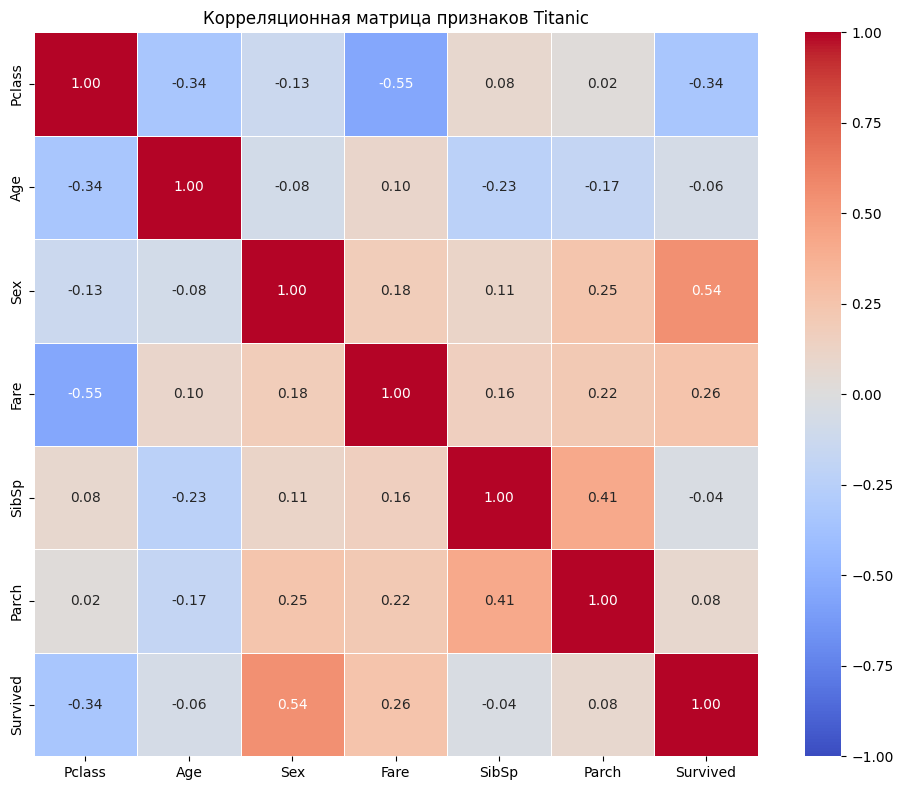

In [11]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5
)

plt.title('Корреляционная матрица признаков Titanic')
plt.tight_layout()
plt.show()